In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline


In [2]:
amazon_original_df = pd.read_csv("amz_uk_price_prediction_dataset.csv")
amazon_original_df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [3]:
amazon_df = amazon_original_df.copy()

In [24]:
crosstab_result = pd.crosstab(amazon_df['category'], amazon_df['isBestSeller'])

#order true values descendent (True is boolean not an string)
crosstab_result = crosstab_result.sort_values(by=True, ascending=False)

crosstab_result

isBestSeller,False,True
category,,
Grocery,9008,556
Health & Personal Care,9017,552
Baby,14709,341
Sports & Outdoors,835935,330
Power & Hand Tools,8353,306
...,...,...
Downhill Ski Boots,1284,0
Digital Frames,774,0
Motorbike Chassis,107,0


In [16]:
best_seller_proportion = crosstab_result[True] / (crosstab_result[True] + crosstab_result[False])
crosstab_result["proportion"] = best_seller_proportion

best_seller_proportion.sort_values(ascending=False)

category
Grocery                                    0.058135
Smart Home Security & Lighting             0.057692
Health & Personal Care                     0.057686
Mobile Phone Accessories                   0.042471
Power & Hand Tools                         0.035339
                                             ...   
Vases                                      0.000000
Blank Media Cases & Wallets                0.000000
Bedding Collections                        0.000000
Internal TV Tuner & Video Capture Cards    0.000000
eBook Readers & Accessories                0.000000
Length: 296, dtype: float64

In [28]:
crosstab_result2 = crosstab_result.copy()
crosstab_result2["proportion"] = (
    crosstab_result2[True] /
    (crosstab_result2[True] + crosstab_result2[False])
)
crosstab_result2 = crosstab_result2.sort_values(
    by="proportion",
    ascending=False
)
crosstab_result2

isBestSeller,False,True,proportion
category,,,
Grocery,9008,556,0.058135
Smart Home Security & Lighting,98,6,0.057692
Health & Personal Care,9017,552,0.057686
Mobile Phone Accessories,248,11,0.042471
Power & Hand Tools,8353,306,0.035339
...,...,...,...
Vases,250,0,0.000000
Blank Media Cases & Wallets,243,0,0.000000
Bedding Collections,6309,0,0.000000


There are no categorys whith best seller being more prevalent

In [29]:
from scipy.stats import chi2_contingency

chi2_statistic, chi2_p_value, _, _ = chi2_contingency(crosstab_result)

chi2_statistic, chi2_p_value

(np.float64(36540.202700613874), np.float64(0.0))

In [30]:
from scipy.stats.contingency import association

association(crosstab_result, method="cramer")

0.12228294397605641

Weak association betweern category and best seller

<Axes: xlabel='category'>

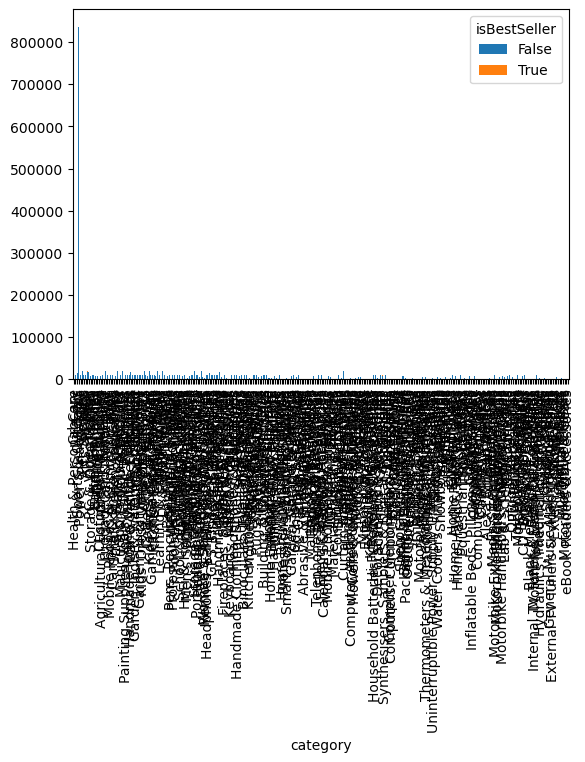

In [31]:
# Plotting a stacked bar chart for the 'crosstab_result' data

crosstab_result.plot(kind="bar", stacked=True)

<Axes: xlabel='category'>

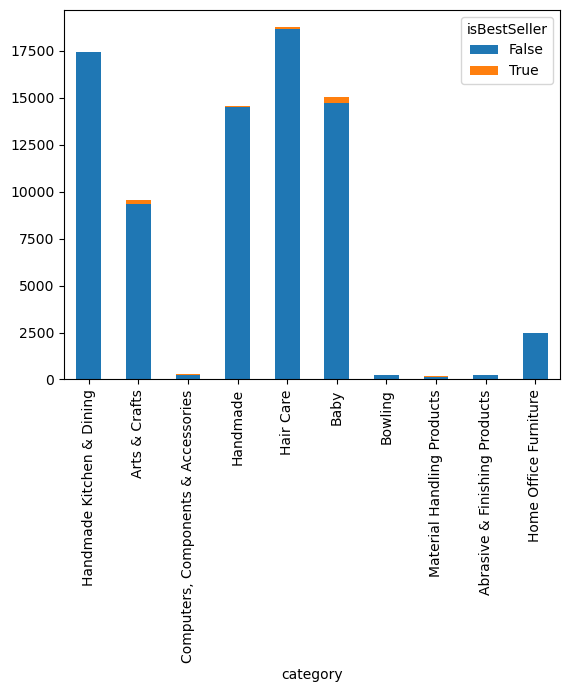

In [33]:
# Making a graph for only 10 categories
crosstab_random = crosstab_result.sample(n=10)
crosstab_random.plot(kind="bar", stacked=True)

## Part 2

In [59]:
def tukeys_test_outliers(data):
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1
    
    # Define bounds for the outliers
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Identify the outliers
    outliers = data[(data < lower_bound) | (data > upper_bound)]
    
    return outliers

In [60]:
data_series = amazon_df['price']  # replace 'ColumnName' with your specific column
outliers = tukeys_test_outliers(data_series)
print(outliers)

10         139.00
19         164.99
25         149.99
28         289.00
31         199.99
            ...  
2443619    166.99
2443627    152.58
2443638    108.77
2443641    166.99
2443643    158.99
Name: price, Length: 327688, dtype: float64


In [62]:
outliers_df = amazon_df[amazon_df["price"].isin(outliers)]

outliers_df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
10,11,B08VDNCZT9,JBL Charge 5 - Portable Bluetooth Speaker with...,4.8,11920,139.00,False,0,Hi-Fi Speakers
19,20,B07NQCKJSH,Echo Studio | Our best-sounding Wi-Fi and Blue...,4.5,14222,164.99,False,0,Hi-Fi Speakers
25,26,B0BLS36M5R,All-new Echo Show 8 | 3rd generation (2023 rel...,0.0,0,149.99,False,0,Hi-Fi Speakers
28,29,B096G3R7C3,JBL PartyBox110 Portable Indoor and Outdoor Pa...,4.8,153,289.00,False,0,Hi-Fi Speakers
31,32,B08MQRDDYB,"Echo Show 15 | Full HD 15.6"" smart display wit...",4.4,2616,199.99,False,0,Hi-Fi Speakers


In [76]:
top_20_categories = outliers_df["category"].value_counts().head(20).index

outliers_top_20 = outliers_df[
    outliers_df["category"].isin(top_20_categories)
]

C:\Users\jejoc\AppData\Local\Temp\ipykernel_41280\418097822.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=outliers_top_20 , x='category', y='price', palette="coolwarm")


<Axes: xlabel='category', ylabel='price'>

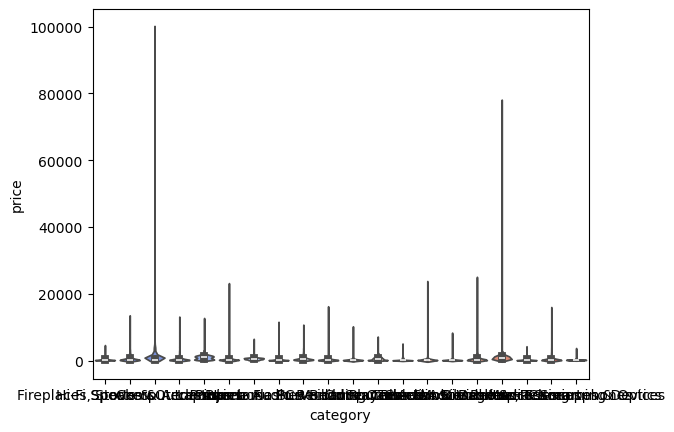

In [78]:
# Plotting a violin plot to visualize the distribution of 'SalePrice' for each 'MSZoning' category, using the "coolwarm" color palette
sns.violinplot(data=outliers_top_20 , x='category', y='price', palette="coolwarm")

In [80]:
top_10_categories = outliers_df["category"].value_counts().head(10).index

outliers_top_10 = outliers_df[
    outliers_df["category"].isin(top_10_categories)
]

C:\Users\jejoc\AppData\Local\Temp\ipykernel_41280\698960824.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=outliers_top_10  , x='category', y='price', palette="coolwarm")


([0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
 [Text(0, 0, 'Sports & Outdoors'),
  Text(1, 0, 'Computer Printers'),
  Text(2, 0, 'Laptops'),
  Text(3, 0, 'Projectors'),
  Text(4, 0, 'Barebone PCs'),
  Text(5, 0, 'Home Audio Record Players'),
  Text(6, 0, 'Monitors'),
  Text(7, 0, 'Garden Storage & Housing'),
  Text(8, 0, 'Desktop PCs'),
  Text(9, 0, 'Binoculars, Telescopes & Optics')])

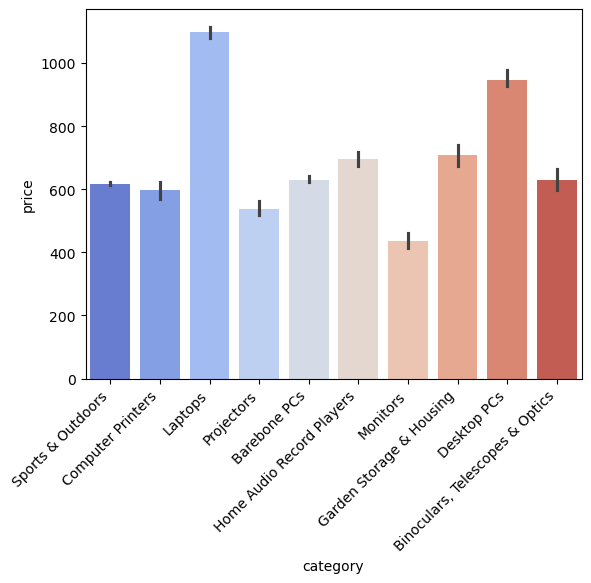

In [83]:
# Plotting a bar plot to visualize the average 'SalePrice' for each 'MSZoning' category, using the "coolwarm" color palette
sns.barplot(data=outliers_top_10  , x='category', y='price', palette="coolwarm")
plt.xticks(rotation=45, ha="right")

The highest avg vale is in laptops

C:\Users\jejoc\AppData\Local\Temp\ipykernel_41280\291186901.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=outliers_top_10, x='category', y='stars', palette="coolwarm")


([0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
 [Text(0, 0, 'Sports & Outdoors'),
  Text(1, 0, 'Computer Printers'),
  Text(2, 0, 'Laptops'),
  Text(3, 0, 'Projectors'),
  Text(4, 0, 'Barebone PCs'),
  Text(5, 0, 'Home Audio Record Players'),
  Text(6, 0, 'Monitors'),
  Text(7, 0, 'Garden Storage & Housing'),
  Text(8, 0, 'Desktop PCs'),
  Text(9, 0, 'Binoculars, Telescopes & Optics')])

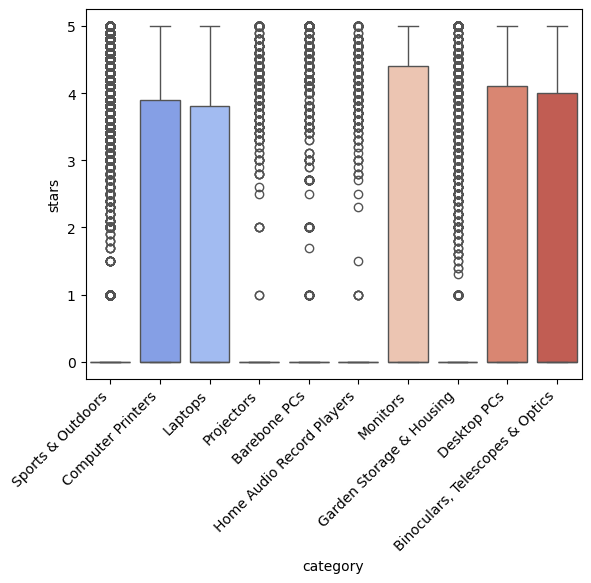

In [85]:
# Plotting a box plot to visualize the spread and outliers of 'SalePrice' for each 'MSZoning' category, using the "coolwarm" color palette
sns.boxplot(data=outliers_top_10, x='category', y='stars', palette="coolwarm")
plt.xticks(rotation=45, ha="right")

## Part 3

In [87]:
# Calculating the Pearson correlation coefficient between 'SalePrice' and 'GrLivArea' columns
correlation = amazon_df['price'].corr(amazon_df['stars'])
correlation

np.float64(-0.12490673262148638)

In [88]:
correlation2 = amazon_df['price'].corr(amazon_df['stars'], method='spearman')
correlation2

np.float64(-0.13316425462433912)

The correlations indicates a no linear correlation trending to the negative

<Axes: xlabel='stars', ylabel='price'>

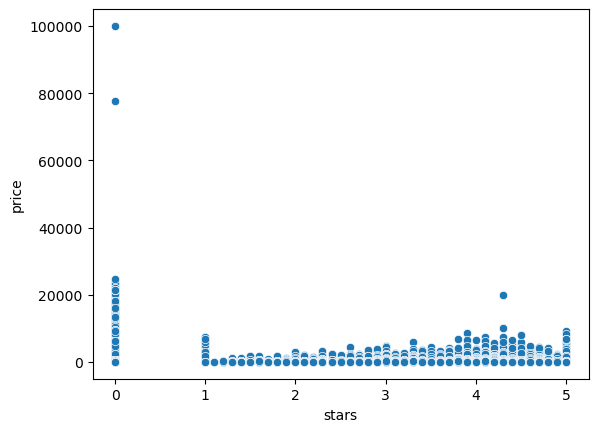

In [91]:
# Plotting a scatter plot to visualize the relationship between 'GrLivArea' and 'SalePrice'
sns.scatterplot(data=amazon_df, x='stars', y='price')

observation need to filter for a smaller difference of values to understand better but we cas se that most of the stared products are between 0 an 20.000$

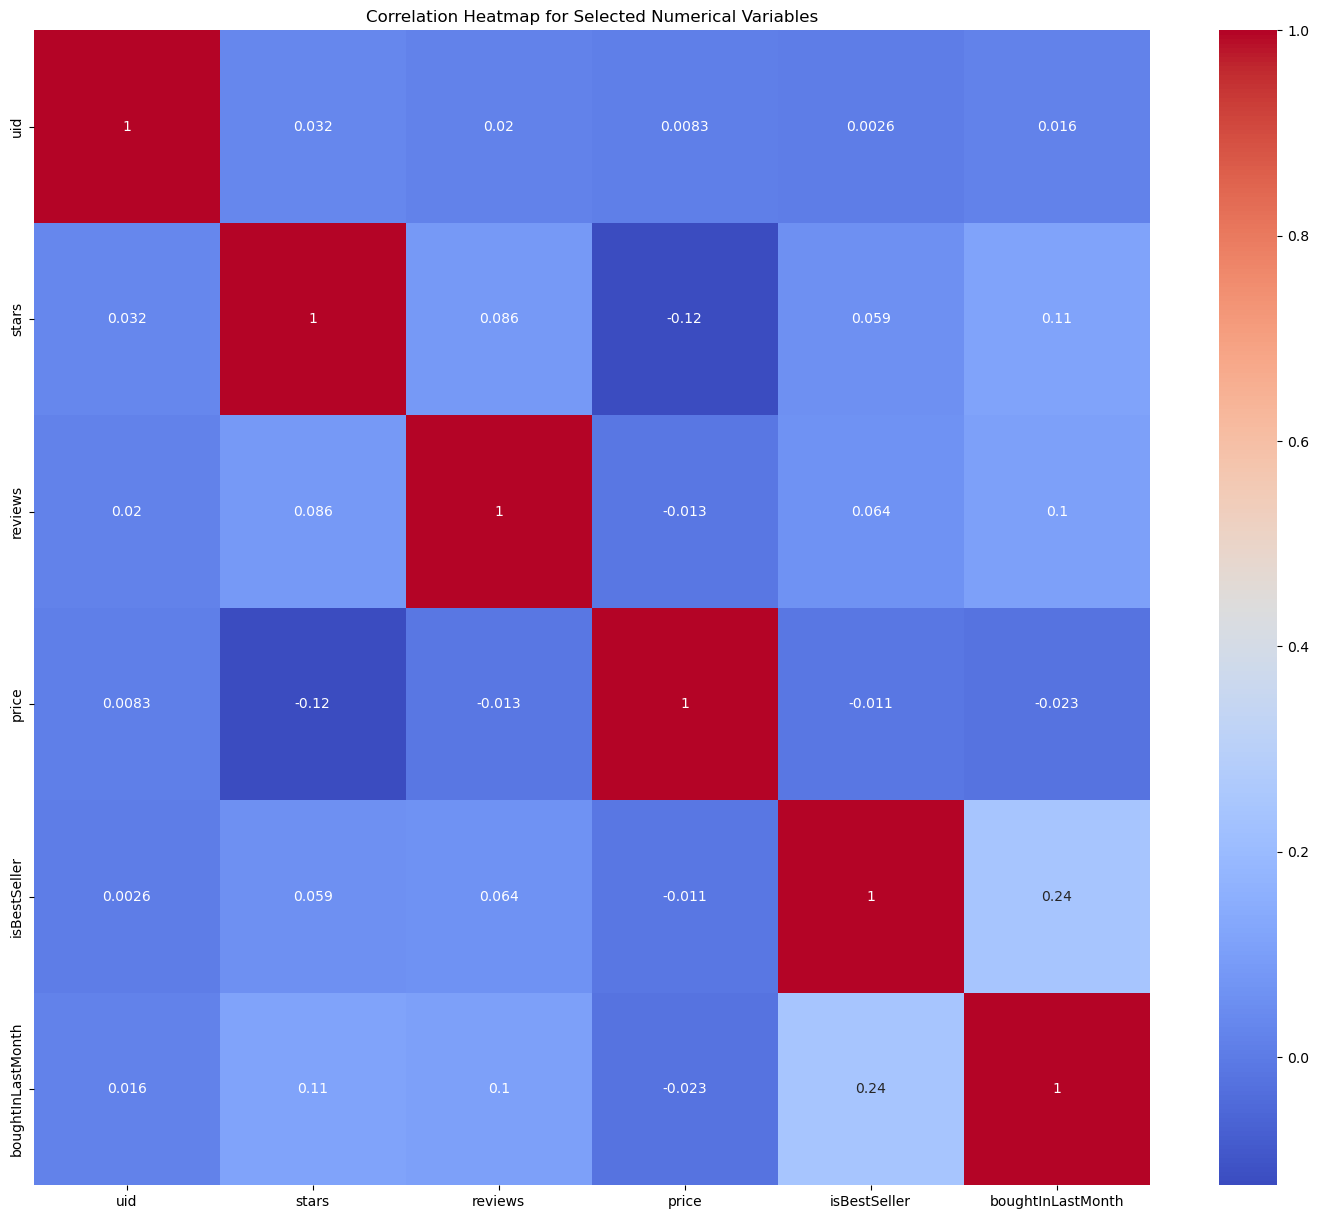

In [96]:
correlation_matrix = amazon_df.corr(numeric_only=True)

# Setting up the matplotlib figure with an appropriate size
plt.figure(figsize=(18, 15))

# Drawing the heatmap for the numerical columns
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm")

plt.title("Correlation Heatmap for Selected Numerical Variables")
plt.show()

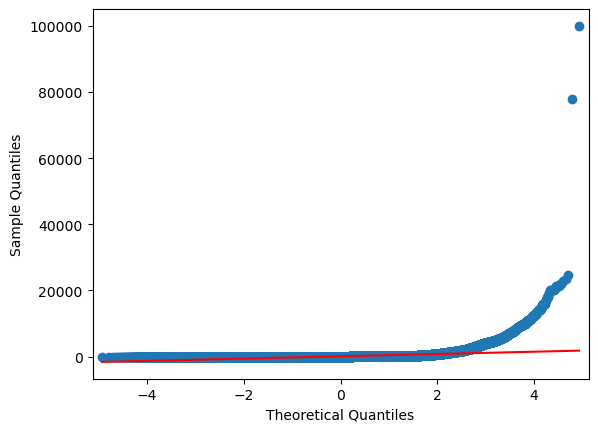

In [97]:
import statsmodels.api as sm

# Generating a Q-Q plot for 'SalePrice' to check if its distribution follows a normal distribution
sm.qqplot(amazon_df['price'], line='s');